# Patient satisfaction: predictor groups and combinations

**Research question:** How well do hospital characteristics, quality performance, clinical outcomes, and Medicare spending—individually and in combination—predict overall patient satisfaction at U.S. hospitals?

The EDA organizes the original eight predictors into four groups: hospital characteristics, quality performance, clinical outcomes, and Medicare spending. It examines data coverage, individual associations, correlations among numeric predictors, and satisfaction within combinations of predictor categories. These descriptive comparisons cannot establish predictive improvement or causation. Models and cross-validation remain pending.

Only the original selected predictors enter the main analysis. The broader HCAHPS correlation search is retained as a supplemental appendix, not used to select predictors for the main question. Training-only missing-value preparation is retained separately from observed-data summaries.

**Team members:** Not yet supplied.  
**Repository:** https://github.com/emmchung/Patient-Hospital-Satisfaction

## Setup

Dependencies and relative paths for the four supplied CMS files.

In [1]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."
DATA_FILES = {
    "hcahps": Path("data/HCAHPS-Hospital.csv"),
    "general": Path("data/Hospital_General_Information.csv"),
    "outcomes": Path("data/Complications_and_Deaths-Hospital.csv"),
    "spending": Path("data/Medicare_Hospital_Spending_Per_Patient-Hospital.csv"),
}
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")


Python 3.9.6 | pandas 2.3.3 | NumPy 2.0.2 | scikit-learn 1.6.1


## Load data

All columns are initially read as text. This preserves leading zeros in hospital identifiers and keeps CMS labels such as “Not Available” distinct from empty fields. Source files are not modified. File hashes identify exactly which downloads produced these results; the download dates and release dates were not provided.

In [2]:
datasets = {
    name: pd.read_csv(path, dtype="string", keep_default_na=False, encoding="utf-8-sig")
    for name, path in DATA_FILES.items()
}
file_summary = pd.DataFrame([
    {"dataset": name, "file": path.name, "rows": len(datasets[name]),
     "columns": datasets[name].shape[1],
     "unique_hospitals": datasets[name]["Facility ID"].nunique(),
     "blank_hospital_ids": int(datasets[name]["Facility ID"].str.strip().eq("").sum()),
     "exact_duplicate_rows": int(datasets[name].duplicated().sum()),
     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for name, path in DATA_FILES.items()
])
display(file_summary.drop(columns="sha256"))
display(file_summary[["file", "sha256"]])
for name, df in datasets.items():
    print(f"\n{name}: actual column names and loaded types")
    display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).to_numpy()}))
    display(df.head(2))


,dataset,file,rows,columns,unique_hospitals,blank_hospital_ids,exact_duplicate_rows
0,hcahps,HCAHPS-Hospital.csv,325720,22,4790,0,0
1,general,Hospital_General_Information.csv,5419,38,5419,0,0
2,outcomes,Complications_and_Deaths-Hospital.csv,95800,18,4790,0,0
3,spending,Medicare_Hospital_Spending_Per_Patient-Hospita...,4626,14,4626,0,0


,file,sha256
0,HCAHPS-Hospital.csv,b70e598f29552df302e30ed649d178abd1b3d3c868ae97...
1,Hospital_General_Information.csv,f874f09fef895a1ccf5bb7392dcbb2be05c9860339261b...
2,Complications_and_Deaths-Hospital.csv,2f7112969e2de2a015af8574848973dc48595ca6f2fe03...
3,Medicare_Hospital_Spending_Per_Patient-Hospita...,fcb050fecedd6af494750a7e6c46d992f2b03738f1f145...



hcahps: actual column names and loaded types


,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,HCAHPS Measure ID,string
9,HCAHPS Question,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description,Patient Survey Star Rating,Patient Survey Star Rating Footnote,HCAHPS Answer Percent,HCAHPS Answer Percent Footnote,HCAHPS Linear Mean Value,Number of Completed Surveys,Number of Completed Surveys Footnote,Survey Response Rate Percent,Survey Response Rate Percent Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_A_P,"Patients who reported that their nurses ""Alway...","Nurses ""always"" communicated well",Not Applicable,,76,,Not Applicable,1392,,17,,10/01/2024,09/30/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_SN_P,"Patients who reported that their nurses ""Somet...","Nurses ""sometimes"" or ""never"" communicated well",Not Applicable,,6,,Not Applicable,1392,,17,,10/01/2024,09/30/2025


...

,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,Measure ID,string
9,Measure Name,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Compared to National,Denominator,Score,Lower Estimate,Higher Estimate,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,COMP_HIP_KNEE,Rate of complications for hip/knee replacement...,Not Available,33,3.8,Not Available,Not Available,,04/01/2023,03/31/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,Not Available,4972,4.4,Not Available,Not Available,,07/01/2024,06/30/2025



spending: actual column names and loaded types


,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,Measure ID,string
9,Measure Name,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Score,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,MSPB-1,Medicare hospital spending per patient (Medica...,0.99,,01/01/2024,12/31/2024
1,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,(256) 593-8310,MSPB-1,Medicare hospital spending per patient (Medica...,1.00,,01/01/2024,12/31/2024


The files have different units of observation. General Information describes hospitals, while HCAHPS and Complications and Deaths contain multiple measures for each hospital. A repeated hospital identifier in these long-format datasets is expected; repeating the same hospital–measure pair would require investigation.

In [3]:
key_definitions = {"hcahps": ["Facility ID", "HCAHPS Measure ID"],
                   "general": ["Facility ID"],
                   "outcomes": ["Facility ID", "Measure ID"],
                   "spending": ["Facility ID", "Measure ID"]}
key_audit = pd.DataFrame([
    {"dataset": name, "key": " + ".join(keys),
     "rows_with_repeated_key": int(datasets[name].duplicated(keys, keep=False).sum())}
    for name, keys in key_definitions.items()
])
display(key_audit)


,dataset,key,rows_with_repeated_key
0,hcahps,Facility ID + HCAHPS Measure ID,0
1,general,Facility ID,0
2,outcomes,Facility ID + Measure ID,0
3,spending,Facility ID + Measure ID,0


## Prepare data

Identify the target, select the agreed predictors, validate hospital-level joins, and handle missing values without fitting a prediction model. The original descriptive table is retained.

### Identify the satisfaction target

The target is the observed measure **`H_HSP_RATING_LINEAR_SCORE`**, labeled **“Overall hospital rating - linear mean score”**, using **`HCAHPS Linear Mean Value`**. This is separate from the star rating and the percentages of patients choosing individual rating categories. The intended scale is 0–100; the code checks the observed values against that range. No individual patient responses are available in these aggregate files.

In [4]:
hcahps = datasets["hcahps"]
rating_measures = hcahps.loc[
    hcahps["HCAHPS Measure ID"].str.startswith("H_HSP_RATING"),
    ["HCAHPS Measure ID", "HCAHPS Question", "HCAHPS Answer Description"]
].drop_duplicates()
display(rating_measures)
TARGET_MEASURE = "H_HSP_RATING_LINEAR_SCORE"
TARGET_COLUMN = "HCAHPS Linear Mean Value"
target_rows = hcahps.loc[hcahps["HCAHPS Measure ID"].eq(TARGET_MEASURE)].copy()
assert not target_rows.empty, "Target measure is absent."
assert not target_rows["Facility ID"].duplicated().any(), "Target is not unique per hospital."
raw_target = target_rows[TARGET_COLUMN].str.strip()
target_numeric = pd.to_numeric(raw_target, errors="coerce")
invalid = target_numeric.notna() & ~target_numeric.between(0, 100)
print("Target rows:", len(target_rows))
print("Numeric target values:", int(target_numeric.notna().sum()))
print("Missing/non-numeric target values:", int(target_numeric.isna().sum()))
print("Outside intended 0–100 range:", int(invalid.sum()))
display(raw_target[target_numeric.isna()].value_counts(dropna=False).to_frame("rows"))
display(target_numeric.describe().to_frame("hospital_rating_linear_score"))


,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description
57,H_HSP_RATING_0_6,Patients who gave their hospital a rating of 6...,"Patients who gave a rating of ""6"" or lower (low)"
58,H_HSP_RATING_7_8,Patients who gave their hospital a rating of 7...,"Patients who gave a rating of ""7"" or ""8"" (medium)"
59,H_HSP_RATING_9_10,Patients who gave their hospital a rating of 9...,"Patients who gave a rating of ""9"" or ""10"" (high)"
60,H_HSP_RATING_LINEAR_SCORE,Overall hospital rating - linear mean score,Overall hospital rating - linear mean score
61,H_HSP_RATING_STAR_RATING,Overall hospital rating - star rating,Overall hospital rating - star rating


Target rows: 4790
Numeric target values: 3183
Missing/non-numeric target values: 1607
Outside intended 0–100 range: 0


,rows
HCAHPS Linear Mean Value,
Not Available,1607


,hospital_rating_linear_score
count,3183.0
mean,87.880616
std,3.583284
min,69.0
25%,86.0
50%,88.0
75%,90.0
max,98.0


### Select the agreed predictors

The three hospital characteristics come from General Information. For Mortality, Safety, and Readmission performance, the source provides counts of measures rated Better, No Different, or Worse. Each group is summarized as **Better ÷ (Better + No Different + Worse)**. This is the proportion of *classified* measures rated better, not a patient outcome rate. It avoids treating an unclassified measure as a poor result. The number of classified measures and the facility measure count are retained for audit. A zero denominator produces a missing proportion.

Only `Hybrid_HWM` and `MSPB-1` are selected from the outcome and spending files. Their numeric values come from `Score`. Other individual clinical measures, other HCAHPS measures, and the overall hospital star rating are excluded from predictor analysis.

In [5]:
general = datasets["general"]
characteristics = ["Hospital Type", "Hospital Ownership", "Emergency Services"]
performance_groups = {"Mortality": "MORT", "Safety": "Safety", "Readmission": "READM"}
raw_performance_columns = [
    column for prefix in performance_groups.values()
    for column in [f"Count of Facility {prefix} Measures", f"Count of {prefix} Measures Better",
                   f"Count of {prefix} Measures No Different", f"Count of {prefix} Measures Worse"]
]
selected_general = general[["Facility ID"] + characteristics + raw_performance_columns].copy()
assert selected_general["Facility ID"].is_unique
performance_audit = []
performance_features = []
for group, prefix in performance_groups.items():
    count_cols = [f"Count of {prefix} Measures {label}" for label in ["Better", "No Different", "Worse"]]
    counts = selected_general[count_cols].apply(pd.to_numeric, errors="coerce")
    classified = counts.sum(axis=1, min_count=3)
    facility_count = pd.to_numeric(selected_general[f"Count of Facility {prefix} Measures"], errors="coerce")
    feature = f"{group} better proportion"
    performance_features.append(feature)
    selected_general[feature] = counts.iloc[:, 0].div(classified.where(classified.gt(0)))
    selected_general[f"{group} classified measures"] = classified
    comparable = classified.notna() & facility_count.notna()
    performance_audit.append({"group": group, "hospitals_with_zero_classified": int(classified.eq(0).sum()),
                              "hospitals_with_incomplete_counts": int(counts.isna().any(axis=1).sum()),
                              "classified_differs_from_facility_count": int((comparable & classified.ne(facility_count)).sum())})
display(pd.DataFrame(performance_audit))

def select_measure(dataset_name, measure_id, output_name):
    selected = datasets[dataset_name].loc[datasets[dataset_name]["Measure ID"].eq(measure_id)].copy()
    assert not selected.empty, f"Missing measure: {measure_id}"
    assert selected["Facility ID"].is_unique, f"Repeated hospital rows for {measure_id}"
    selected[output_name] = pd.to_numeric(selected["Score"].str.strip(), errors="coerce")
    return selected

hybrid = select_measure("outcomes", "Hybrid_HWM", "Hybrid_HWM")
spending = select_measure("spending", "MSPB-1", "MSPB-1")
for name, selected in [("Hybrid_HWM", hybrid), ("MSPB-1", spending)]:
    display(selected[["Measure ID", "Measure Name", "Start Date", "End Date"]].drop_duplicates())
    print(f"{name}: nonnumeric score labels")
    display(selected.loc[selected[name].isna(), "Score"].value_counts().to_frame("rows"))


,group,hospitals_with_zero_classified,hospitals_with_incomplete_counts,classified_differs_from_facility_count
0,Mortality,0,1323,0
1,Safety,0,2075,0
2,Readmission,0,1155,0


,Measure ID,Measure Name,Start Date,End Date
1,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,07/01/2024,06/30/2025


Hybrid_HWM: nonnumeric score labels


,rows
Score,
Not Available,529


,Measure ID,Measure Name,Start Date,End Date
0,MSPB-1,Medicare hospital spending per patient (Medica...,01/01/2024,12/31/2024


MSPB-1: nonnumeric score labels


,rows
Score,
Not Available,1754


### Build a descriptive hospital-level table and check coverage

General Information defines the reference hospital list. Left joins preserve all those hospitals, including hospitals without satisfaction scores. Every join is checked as one-to-one; unmatched hospitals are reported. Missing targets and missing predictors remain missing. The target's original reporting status is kept separate from an absent HCAHPS target row.

In [6]:
target_view = target_rows[["Facility ID", "Start Date", "End Date"]].copy()
target_view["Hospital rating linear score"] = target_numeric
target_view["target_row_present"] = True
analysis = selected_general.merge(target_view[["Facility ID", "Hospital rating linear score", "target_row_present"]],
                                 on="Facility ID", how="left", validate="one_to_one")
for selected, feature in [(hybrid, "Hybrid_HWM"), (spending, "MSPB-1")]:
    analysis = analysis.merge(selected[["Facility ID", feature]], on="Facility ID", how="left", validate="one_to_one")
features = characteristics + performance_features + ["Hybrid_HWM", "MSPB-1"]
for col in characteristics:
    cleaned = analysis[col].str.strip()
    analysis[col] = cleaned.mask(cleaned.str.casefold().isin(["", "not available", "not applicable"]))
coverage = pd.DataFrame([
    {"selected_measure": name, "source_hospitals": selected["Facility ID"].nunique(),
     "outside_reference_list": int((~selected["Facility ID"].isin(general["Facility ID"])).sum())}
    for name, selected in [("Target", target_view), ("Hybrid_HWM", hybrid), ("MSPB-1", spending)]
])
display(coverage)
print("Reference hospitals:", len(analysis))
print("No HCAHPS target row:", int(analysis["target_row_present"].isna().sum()))
print("Present target row but no numeric target:", int((analysis["target_row_present"].eq(True) & analysis["Hospital rating linear score"].isna()).sum()))
periods = []
for label, frame in [("Target", target_view), ("Hybrid_HWM", hybrid), ("MSPB-1", spending)]:
    part = frame[["Start Date", "End Date"]].drop_duplicates().copy()
    part.insert(0, "measure", label)
    periods.append(part)
display(pd.concat(periods, ignore_index=True))


,selected_measure,source_hospitals,outside_reference_list
0,Target,4790,0
1,Hybrid_HWM,4790,0
2,MSPB-1,4626,0


Reference hospitals: 5419
No HCAHPS target row: 629
Present target row but no numeric target: 1607


,measure,Start Date,End Date
0,Target,10/01/2024,09/30/2025
1,Hybrid_HWM,07/01/2024,06/30/2025
2,MSPB-1,01/01/2024,12/31/2024


### Resolve missing values for subsequent analysis

**Target:** Hospitals without a numeric satisfaction target are excluded from the supervised sample. Targets are never imputed: invented satisfaction labels would undermine evaluation. The original `analysis` dataframe and earlier descriptive results are retained. Missing targets include both absent HCAHPS rows and rows labeled “Not Available”.

**Predictors:** Hospitals with missing predictors are retained. Numeric predictors use training-set medians and missingness indicators; categorical predictors use an explicit `Missing` category. Indicators allow a later model to distinguish an observed value from an imputed value. A missing performance proportion stays distinct from an observed zero.

To produce usable filled tables without leaking information, an 80/20 hospital split is created solely for data preparation, with a fixed random seed. The imputer learns medians from the training portion only and applies those same medians to the held-out portion. No prediction models are fitted or evaluated. For future cross-validation, the separate, unfitted `preprocessor` must be included inside a model pipeline so medians are relearned in each training fold; the pre-imputed tables must not be used for cross-validation.

Median imputation is a practical starting policy, not proof that missingness is random. Reporting-related selection remains a limitation. The stored hospital IDs are retained separately from predictor values.

In [7]:
numeric_features = performance_features + ["Hybrid_HWM", "MSPB-1"]

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

TARGET = "Hospital rating linear score"
model_data = analysis.loc[analysis[TARGET].notna(), ["Facility ID", TARGET] + features].copy()
assert model_data["Facility ID"].is_unique
assert model_data[TARGET].between(0, 100).all()

# Keep raw predictors for future fold-specific preprocessing.
X = model_data.set_index("Facility ID")[features].copy()
y = model_data.set_index("Facility ID")[TARGET].astype(float)
for column in numeric_features:
    X[column] = pd.to_numeric(X[column], errors="coerce").astype(float)
for column in characteristics:
    values = X[column].astype(object)
    X[column] = values.where(pd.notna(values), np.nan)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
if X_train[numeric_features].isna().all().any():
    raise ValueError("A numeric predictor has no training values; a median cannot be estimated.")

# This template remains unfitted for use inside a future model pipeline.
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_features),
    ("categorical", SimpleImputer(strategy="constant", fill_value="Missing"), characteristics),
], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

# Fit a separate copy for these train/test preparation tables only.
fitted_preprocessor = clone(preprocessor)
X_train_prepared = fitted_preprocessor.fit_transform(X_train)
X_test_prepared = fitted_preprocessor.transform(X_test)
assert not X_train_prepared.isna().any().any()
assert not X_test_prepared.isna().any().any()
assert y_train.notna().all() and y_test.notna().all()
assert set(X_train.index).isdisjoint(X_test.index)
assert X_train_prepared.index.equals(y_train.index)
assert X_test_prepared.index.equals(y_test.index)

sample_flow = pd.DataFrame({
    "stage": ["All reference hospitals", "Excluded: missing target", "Retained: numeric target",
              "Retained with at least one missing predictor", "Training hospitals", "Held-out hospitals"],
    "hospitals": [len(analysis), int(analysis[TARGET].isna().sum()), len(model_data),
                  int(X.isna().any(axis=1).sum()), len(X_train), len(X_test)]
})
display(sample_flow)
imputation_audit = pd.DataFrame({
    "missing_train_before": X_train.isna().sum(),
    "missing_test_before": X_test.isna().sum(),
    "missing_train_after": X_train_prepared[features].isna().sum(),
    "missing_test_after": X_test_prepared[features].isna().sum(),
})
display(imputation_audit)
display(pd.Series(fitted_preprocessor.named_transformers_["numeric"].statistics_,
                  index=numeric_features, name="Training-only replacement median").to_frame())
print("Prepared predictor columns:", X_train_prepared.columns.tolist())
display(X_train_prepared.head())
display(Markdown(
    f"**Missing-value handling completed.** {analysis[TARGET].isna().sum():,} reference hospitals without a numeric target "
    f"are excluded from the supervised sample. All {len(model_data):,} hospitals with numeric targets are retained, "
    f"including {X.isna().any(axis=1).sum():,} with incomplete predictors. "
    f"The prepared training ({len(X_train):,}) and held-out ({len(X_test):,}) predictor tables contain no missing values. "
    "The original dataframe and raw predictors remain available. Categories are not yet encoded, and no prediction model or cross-validation has been run."
))


,stage,hospitals
0,All reference hospitals,5419
1,Excluded: missing target,2236
2,Retained: numeric target,3183
3,Retained with at least one missing predictor,571
4,Training hospitals,2546
5,Held-out hospitals,637


,missing_train_before,missing_test_before,missing_train_after,missing_test_after
Hospital Type,0,0,0,0
Hospital Ownership,0,0,0,0
Emergency Services,0,0,0,0
Mortality better proportion,42,10,0,0
Safety better proportion,128,33,0,0
Readmission better proportion,36,9,0,0
Hybrid_HWM,26,9,0,0
MSPB-1,436,118,0,0


,Training-only replacement median
Mortality better proportion,0.000000
Safety better proportion,0.142857
Readmission better proportion,0.000000
Hybrid_HWM,3.800000
MSPB-1,0.990000


Prepared predictor columns: ['Mortality better proportion', 'Safety better proportion', 'Readmission better proportion', 'Hybrid_HWM', 'MSPB-1', 'missingindicator_Mortality better proportion', 'missingindicator_Safety better proportion', 'missingindicator_Readmission better proportion', 'missingindicator_Hybrid_HWM', 'missingindicator_MSPB-1', 'Hospital Type', 'Hospital Ownership', 'Emergency Services']


,Mortality better proportion,Safety better proportion,Readmission better proportion,Hybrid_HWM,MSPB-1,missingindicator_Mortality better proportion,missingindicator_Safety better proportion,missingindicator_Readmission better proportion,missingindicator_Hybrid_HWM,missingindicator_MSPB-1,Hospital Type,Hospital Ownership,Emergency Services
Facility ID,,,,,,,,,,,,,
531318,0.0,0.142857,0.0,4.0,0.99,1.0,1.0,1.0,0.0,1.0,Critical Access Hospitals,Government - Hospital District or Authority,Yes
090001,0.0,0.250000,0.0,3.5,0.98,0.0,0.0,0.0,0.0,0.0,Acute Care Hospitals,Proprietary,Yes
440218,0.0,0.142857,0.0,3.4,0.99,1.0,1.0,1.0,0.0,1.0,Acute Care Hospitals,Voluntary non-profit - Other,No
440176,0.0,0.000000,0.0,3.9,0.99,0.0,0.0,0.0,0.0,0.0,Acute Care Hospitals,Voluntary non-profit - Private,Yes
300012,0.0,0.125000,0.1,4.9,1.01,0.0,0.0,0.0,0.0,0.0,Acute Care Hospitals,Voluntary non-profit - Private,Yes


**Missing-value handling completed.** 2,236 reference hospitals without a numeric target are excluded from the supervised sample. All 3,183 hospitals with numeric targets are retained, including 571 with incomplete predictors. The prepared training (2,546) and held-out (637) predictor tables contain no missing values. The original dataframe and raw predictors remain available. Categories are not yet encoded, and no prediction model or cross-validation has been run.

## Explore data

Summaries and plots below use observed values in the descriptive dataframe, not imputed values. The held-out split is reserved for future model evaluation; these full-sample descriptive results are exploratory.

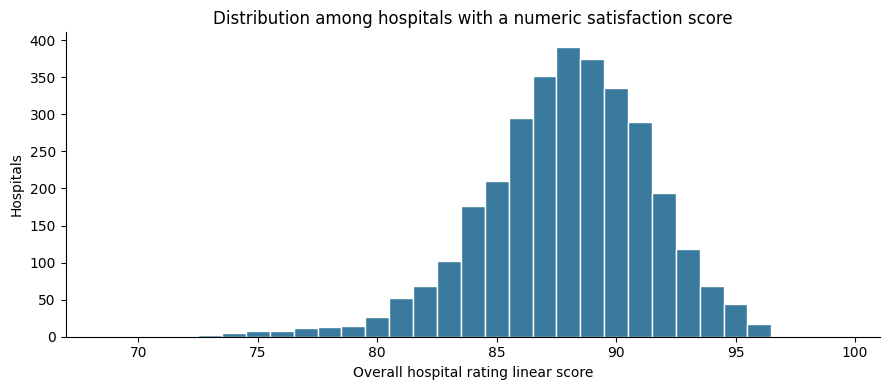

In [8]:
fig, ax = plt.subplots()
ax.hist(target_numeric.dropna().astype(float), bins=np.arange(68.5, 100.5, 1), edgecolor="white", color="#397a9e")
ax.set(xlabel="Overall hospital rating linear score", ylabel="Hospitals",
       title="Distribution among hospitals with a numeric satisfaction score")
plt.tight_layout()
plt.show()


In [9]:
display(Markdown(
    f"**Target findings.** {target_numeric.notna().sum():,} of {len(target_rows):,} hospitals "
    f"({target_numeric.notna().mean():.1%}) have numeric scores; "
    f"{target_numeric.isna().sum():,} ({target_numeric.isna().mean():.1%}) do not. "
    f"Among reported scores, the mean is {target_numeric.mean():.2f}, the median is "
    f"{target_numeric.median():.1f}, and the observed range is "
    f"{target_numeric.min():.0f}–{target_numeric.max():.0f}. "
    "These summaries exclude unavailable scores and should not be interpreted as the satisfaction of hospitals without reported scores."
))


**Target findings.** 3,183 of 4,790 hospitals (66.5%) have numeric scores; 1,607 (33.5%) do not. Among reported scores, the mean is 87.88, the median is 88.0, and the observed range is 69–98. These summaries exclude unavailable scores and should not be interpreted as the satisfaction of hospitals without reported scores.

### Missingness in the selected predictors

Availability is shown for all reference hospitals and separately for hospitals with a numeric target—the subset that could support a later supervised analysis. Missing values here include absent measure rows as well as present rows with unavailable numeric values. Raw General Information counts and their labels are audited separately; none are imputed.

,all_hospitals,missing_all,missing_all_percent,hospitals_with_target,missing_with_target,missing_with_target_percent
Hospital Type,5419,0,0.000000,3183,0,0.000000
Hospital Ownership,5419,0,0.000000,3183,0,0.000000
Emergency Services,5419,0,0.000000,3183,0,0.000000
Mortality better proportion,5419,1323,24.414099,3183,52,1.633679
Safety better proportion,5419,2075,38.291198,3183,161,5.058121
Readmission better proportion,5419,1155,21.313896,3183,45,1.413761
Hybrid_HWM,5419,1158,21.369256,3183,35,1.099592
MSPB-1,5419,2547,47.001292,3183,554,17.404964


Count of Facility MORT Measures nonnumeric labels: {'Not Available': 1323}
Count of MORT Measures Better nonnumeric labels: {'Not Available': 1323}
Count of MORT Measures No Different nonnumeric labels: {'Not Available': 1323}
Count of MORT Measures Worse nonnumeric labels: {'Not Available': 1323}
Count of Facility Safety Measures nonnumeric labels: {'Not Available': 2075}
Count of Safety Measures Better nonnumeric labels: {'Not Available': 2075}
Count of Safety Measures No Different nonnumeric labels: {'Not Available': 2075}
Count of Safety Measures Worse nonnumeric labels: {'Not Available': 2075}
Count of Facility READM Measures nonnumeric labels: {'Not Available': 1155}
Count of READM Measures Better nonnumeric labels: {'Not Available': 1155}
Count of READM Measures No Different nonnumeric labels: {'Not Available': 1155}
Count of READM Measures Worse nonnumeric labels: {'Not Available': 1155}
Hospitals with target and every selected predictor: 2612


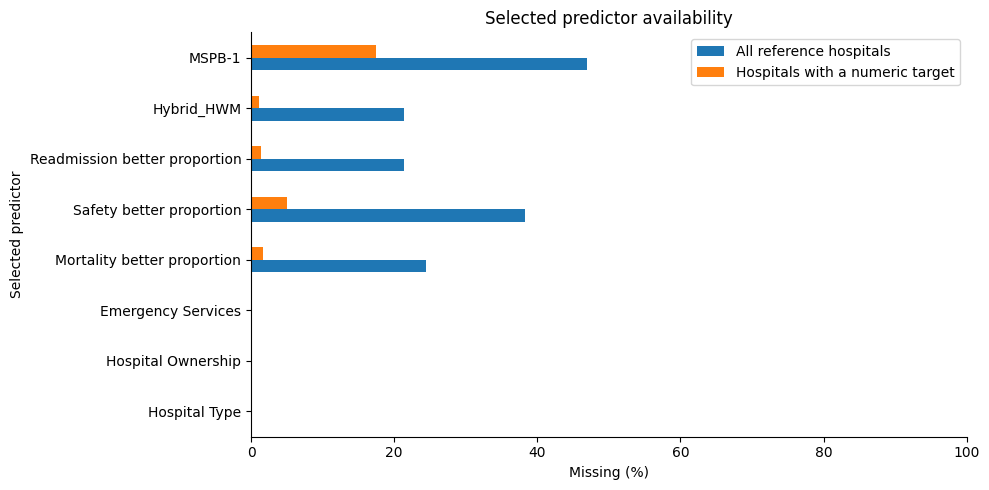

In [10]:
scored = analysis.loc[analysis["Hospital rating linear score"].notna()].copy()
availability = pd.DataFrame({
    "all_hospitals": len(analysis),
    "missing_all": analysis[features].isna().sum(),
    "missing_all_percent": analysis[features].isna().mean() * 100,
    "hospitals_with_target": len(scored),
    "missing_with_target": scored[features].isna().sum(),
    "missing_with_target_percent": scored[features].isna().mean() * 100,
})
display(availability)
for col in raw_performance_columns:
    raw = general[col].str.strip()
    labels = raw[pd.to_numeric(raw, errors="coerce").isna()].value_counts(dropna=False)
    print(col, "nonnumeric labels:", labels.to_dict())
complete_count = int(scored[features].notna().all(axis=1).sum())
print("Hospitals with target and every selected predictor:", complete_count)
ax = availability[["missing_all_percent", "missing_with_target_percent"]].plot.barh(figsize=(10, 5))
ax.set(xlim=(0, 100), xlabel="Missing (%)", ylabel="Selected predictor", title="Selected predictor availability")
ax.legend(["All reference hospitals", "Hospitals with a numeric target"])
plt.tight_layout()
plt.show()


### Satisfaction by hospital characteristics

Tables show both total hospital counts and counts with a reported target. Means, medians, and boxplots use numeric targets only. Differences are descriptive and can reflect patient populations, geography, hospital size, and reporting patterns. They are not adjusted effects.

Hospital Type


,hospitals,numeric_targets,mean_score,median_score,target_available_percent
Hospital Type,,,,,
Acute Care - Department of Defense,32,27,91.37,91.0,84.38
Acute Care - Veterans Administration,132,110,90.45,90.5,83.33
Acute Care Hospitals,3107,2699,87.3,88.0,86.87
Childrens,94,0,<NA>,<NA>,0.0
Critical Access Hospitals,1382,347,91.32,91.0,25.11
Long-term,5,0,<NA>,<NA>,0.0
Psychiatric,624,0,<NA>,<NA>,0.0
Rural Emergency Hospital,43,0,<NA>,<NA>,0.0


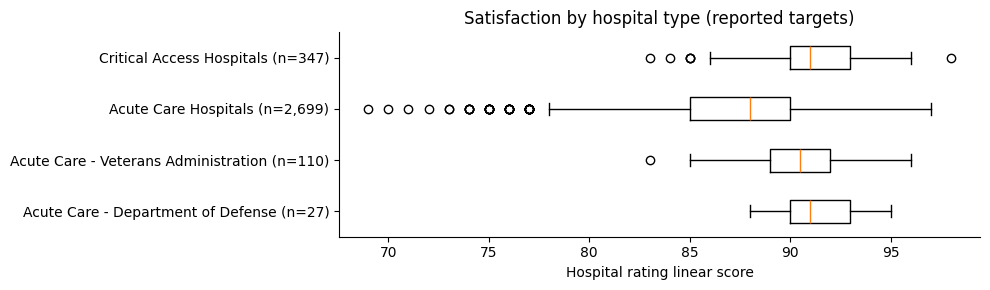

Hospital Ownership


,hospitals,numeric_targets,mean_score,median_score,target_available_percent
Hospital Ownership,,,,,
Department of Defense,32,27,91.37,91.0,84.38
Government - Federal,42,12,87.58,87.5,28.57
Government - Hospital District or Authority,512,204,88.17,88.0,39.84
Government - Local,393,154,88.79,89.0,39.19
Government - State,209,39,87.64,88.0,18.66
Physician,80,50,91.28,92.0,62.5
Proprietary,1063,518,85.84,86.0,48.73
Tribal,17,3,90.33,90.0,17.65
Veterans Health Administration,132,110,90.45,90.5,83.33


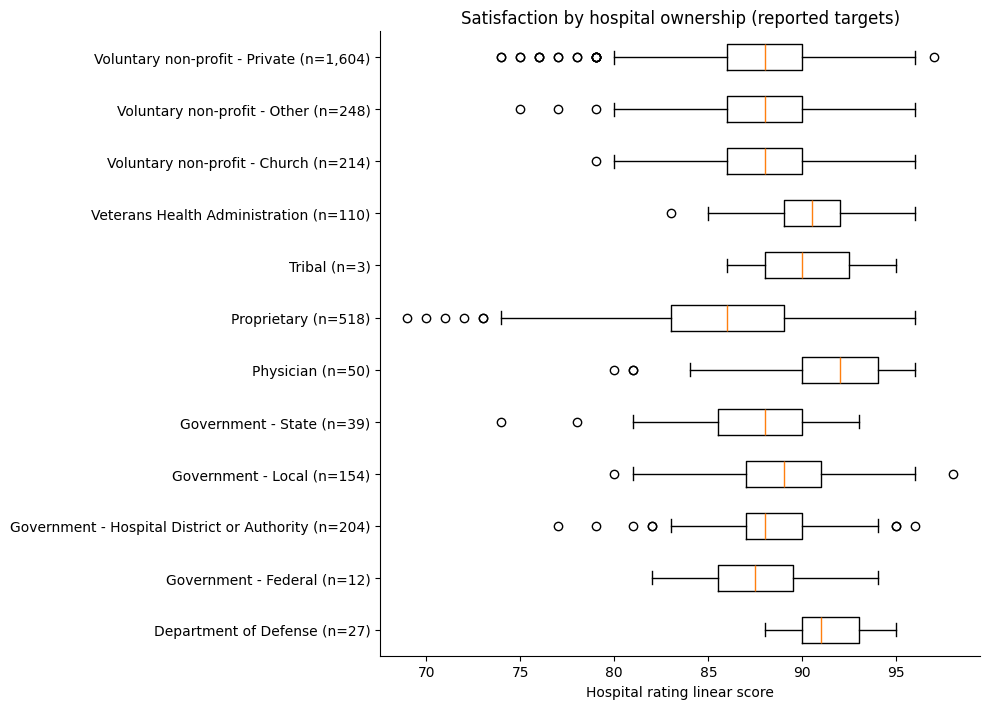

Emergency Services


,hospitals,numeric_targets,mean_score,median_score,target_available_percent
Emergency Services,,,,,
No,924,192,88.95,90.0,20.78
Yes,4495,2991,87.81,88.0,66.54


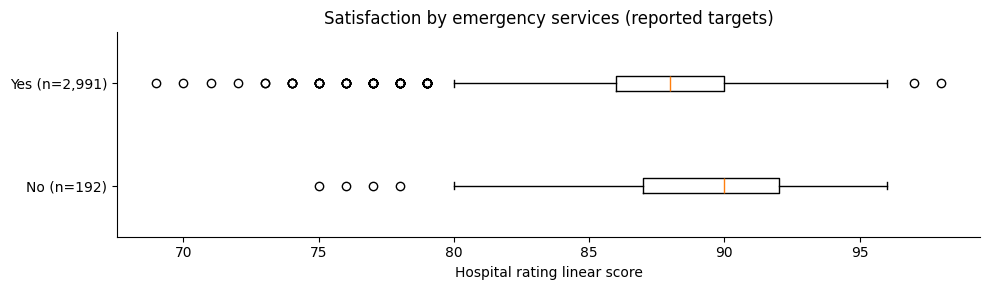

In [11]:
characteristic_summaries = {}
for col in characteristics:
    group_labels = analysis[col].fillna("Missing / unavailable")
    summary = analysis.groupby(group_labels)["Hospital rating linear score"].agg(
        hospitals="size", numeric_targets="count", mean_score="mean", median_score="median")
    summary["target_available_percent"] = 100 * summary["numeric_targets"] / summary["hospitals"]
    characteristic_summaries[col] = summary
    print(col)
    display(summary.round(2))
    groups = [(label, group["Hospital rating linear score"].dropna().astype(float))
              for label, group in analysis.groupby(group_labels)]
    groups = [(label, values) for label, values in groups if len(values)]
    fig, ax = plt.subplots(figsize=(10, max(3, .6 * len(groups))))
    ax.boxplot([values for _, values in groups], vert=False,
               tick_labels=[f"{label} (n={len(values):,})" for label, values in groups])
    ax.set(xlabel="Hospital rating linear score", title=f"Satisfaction by {col.lower()} (reported targets)")
    plt.tight_layout()
    plt.show()


### Satisfaction and numeric predictors

Mortality/Safety/Readmission performance is represented by the better proportion defined above. `Hybrid_HWM` is the reported hybrid hospital-wide mortality measure; `MSPB-1` is the reported spending score. Both are taken directly from their selected score rows, with no fabricated values.

Each scatterplot uses hospitals with both the predictor and the target. Pearson correlation summarizes linear association; Spearman correlation summarizes rank association. Sample sizes differ by predictor. The correlations are unadjusted exploratory summaries and do not measure predictive accuracy or causation. If a predictor has no usable variation or too few observations, its correlation is left undefined.

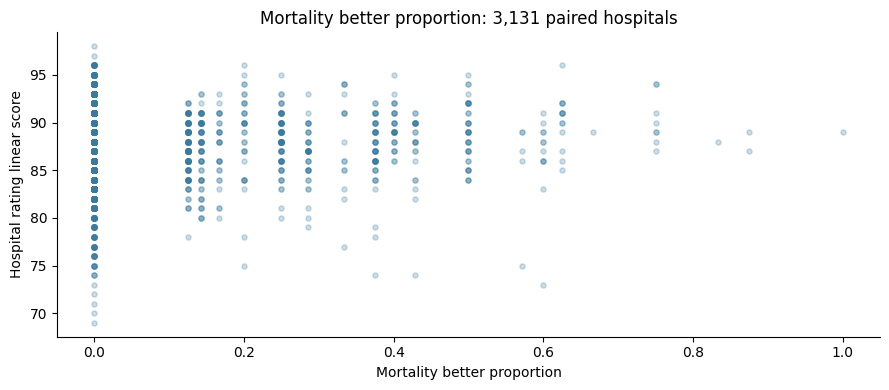

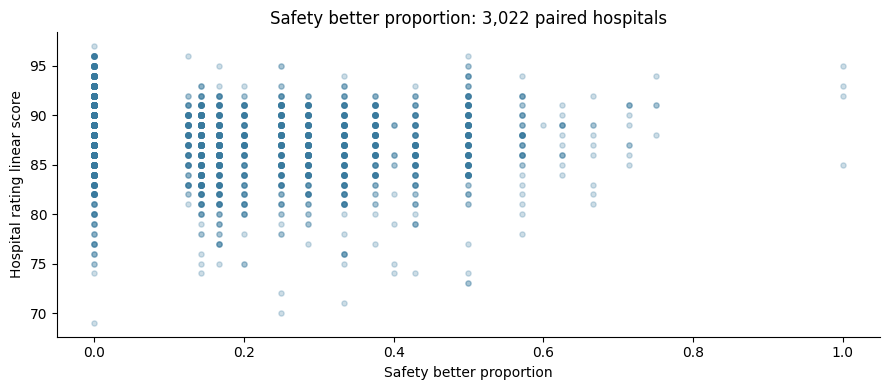

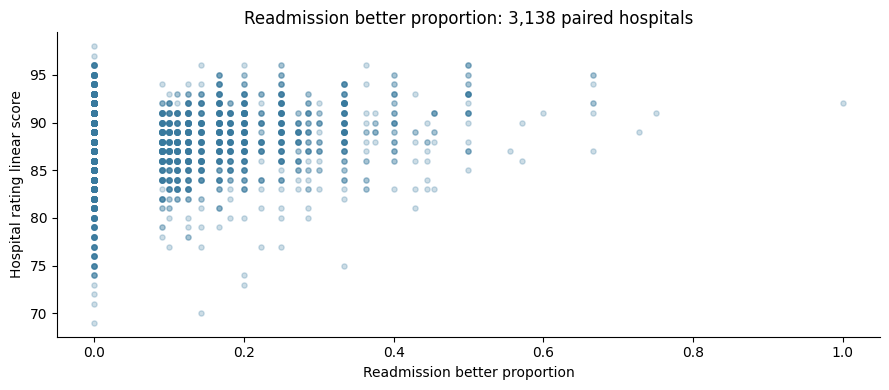

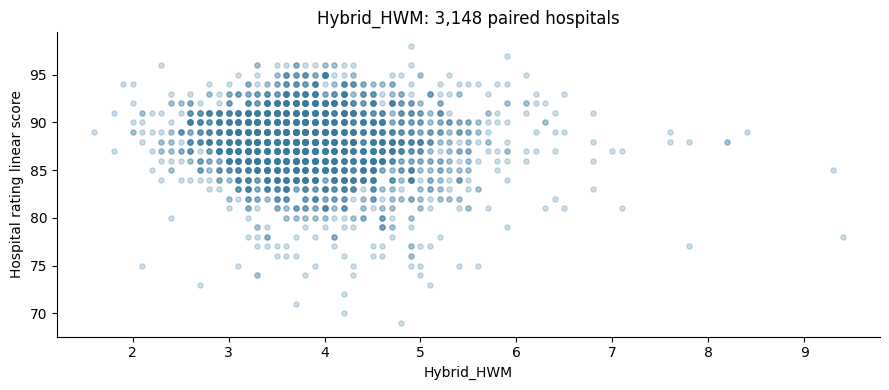

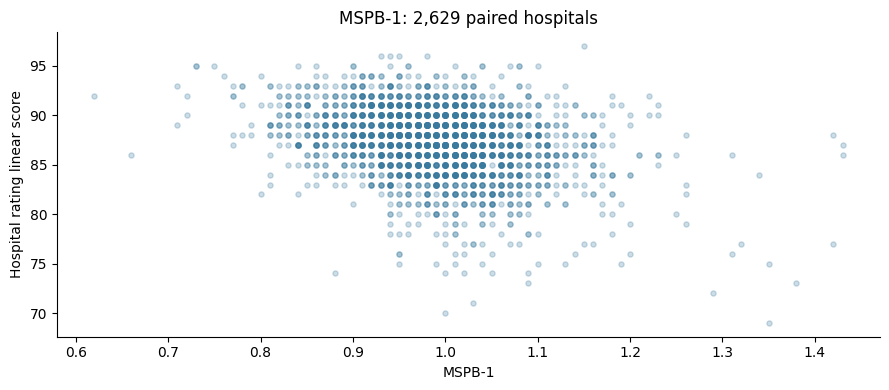

,paired_hospitals,predictor_min,predictor_max,pearson_r,spearman_rho
predictor,,,,,
Mortality better proportion,3131,0.00,1.00,0.019,-0.000
Safety better proportion,3022,0.00,1.00,-0.200,-0.263
Readmission better proportion,3138,0.00,1.00,0.174,0.149
Hybrid_HWM,3148,1.60,9.40,-0.076,-0.056
MSPB-1,2629,0.62,1.43,-0.313,-0.286


In [12]:
numeric_features = performance_features + ["Hybrid_HWM", "MSPB-1"]
relationships = []
for feature in numeric_features:
    pair = scored[[feature, "Hospital rating linear score"]].dropna().astype(float)
    usable = len(pair) >= 3 and pair[feature].nunique() > 1 and pair.iloc[:, 1].nunique() > 1
    relationships.append({"predictor": feature, "paired_hospitals": len(pair),
                          "predictor_min": pair[feature].min(), "predictor_max": pair[feature].max(),
                          "pearson_r": pair[feature].corr(pair.iloc[:, 1]) if usable else np.nan,
                          "spearman_rho": pair[feature].corr(pair.iloc[:, 1], method="spearman") if usable else np.nan})
    fig, ax = plt.subplots()
    if len(pair):
        ax.scatter(pair[feature], pair.iloc[:, 1], alpha=.25, s=14, color="#397a9e")
    ax.set(xlabel=feature, ylabel="Hospital rating linear score", title=f"{feature}: {len(pair):,} paired hospitals")
    if not usable:
        ax.text(.5, .5, "Insufficient observations or variation for correlation", transform=ax.transAxes, ha="center")
    plt.tight_layout()
    plt.show()
relationships = pd.DataFrame(relationships).set_index("predictor")
display(relationships.round(3))


### Predictor groups and fair comparison samples

The four groups below are fixed for the main project. Availability is checked for every nonempty combination of groups, using hospitals with observed targets. These counts describe the cost of a complete-case restriction; they do not impose that restriction. Future model comparisons should use the same hospitals and folds, with preprocessing fitted within each training fold. Group-specific complete-case models would otherwise compare different populations.

In [13]:
from itertools import combinations

predictor_groups = {
    "Hospital characteristics": characteristics,
    "Quality performance": performance_features,
    "Clinical outcomes": ["Hybrid_HWM"],
    "Medicare spending": ["MSPB-1"],
}
display(pd.DataFrame([{"group": group, "variables": ", ".join(columns)}
                      for group, columns in predictor_groups.items()]))
combination_coverage = []
for size in range(1, len(predictor_groups) + 1):
    for combination in combinations(predictor_groups, size):
        columns = [column for group in combination for column in predictor_groups[group]]
        available = scored[columns].notna().all(axis=1)
        combination_coverage.append({"groups": " + ".join(combination), "number_of_groups": size,
                                     "complete_hospitals": int(available.sum()),
                                     "percent_of_target_sample": 100 * available.mean()})
combination_coverage = pd.DataFrame(combination_coverage)
display(combination_coverage.round(1))


,group,variables
0,Hospital characteristics,"Hospital Type, Hospital Ownership, Emergency S..."
1,Quality performance,"Mortality better proportion, Safety better pro..."
2,Clinical outcomes,Hybrid_HWM
3,Medicare spending,MSPB-1


,groups,number_of_groups,complete_hospitals,percent_of_target_sample
0,Hospital characteristics,1,3183,100.0
1,Quality performance,1,3014,94.7
2,Clinical outcomes,1,3148,98.9
3,Medicare spending,1,2629,82.6
4,Hospital characteristics + Quality performance,2,3014,94.7
5,Hospital characteristics + Clinical outcomes,2,3148,98.9
6,Hospital characteristics + Medicare spending,2,2629,82.6
7,Quality performance + Clinical outcomes,2,3014,94.7
8,Quality performance + Medicare spending,2,2612,82.1
9,Clinical outcomes + Medicare spending,2,2629,82.6


### Relationships among the numeric predictors

The heatmap includes the target and the five selected numeric predictors. It helps identify overlap between predictor groups, not just relationships with satisfaction. Each correlation uses the observed pairs available for that comparison; the companion matrix gives the pair counts. These are not adjusted effects or correlations between entire groups.

,Hospital rating linear score,Mortality better proportion,Safety better proportion,Readmission better proportion,Hybrid_HWM,MSPB-1
Hospital rating linear score,1.000,0.019,-0.200,0.174,-0.076,-0.313
Mortality better proportion,0.019,1.000,0.239,0.092,-0.447,0.042
Safety better proportion,-0.200,0.239,1.000,0.013,-0.237,0.189
Readmission better proportion,0.174,0.092,0.013,1.000,-0.140,-0.126
Hybrid_HWM,-0.076,-0.447,-0.237,-0.140,1.000,0.135
MSPB-1,-0.313,0.042,0.189,-0.126,0.135,1.000


,Hospital rating linear score,Mortality better proportion,Safety better proportion,Readmission better proportion,Hybrid_HWM,MSPB-1
Hospital rating linear score,3183,3131,3022,3138,3148,2629
Mortality better proportion,3131,3131,3014,3131,3131,2629
Safety better proportion,3022,3014,3022,3020,3018,2612
Readmission better proportion,3138,3131,3020,3138,3135,2629
Hybrid_HWM,3148,3131,3018,3135,3148,2629
MSPB-1,2629,2629,2612,2629,2629,2629


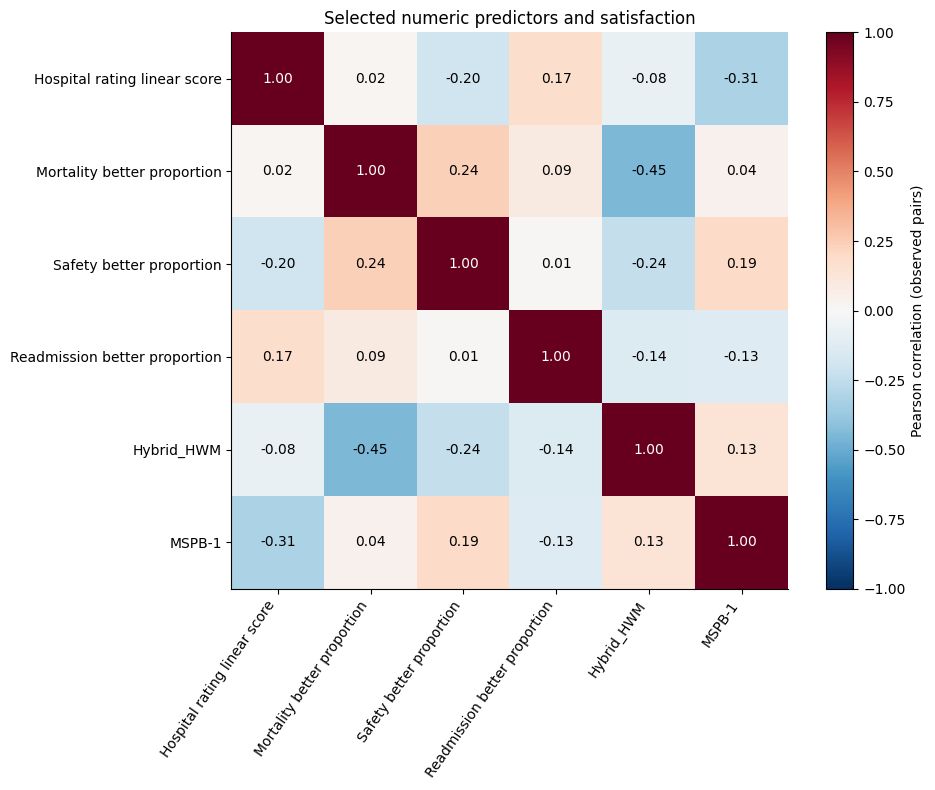

In [14]:
matrix_columns = ["Hospital rating linear score"] + numeric_features
matrix_data = scored[matrix_columns].astype(float)
predictor_correlations = matrix_data.corr(method="pearson", min_periods=100)
observed = matrix_data.notna().astype(int)
pair_counts = observed.T.dot(observed)
display(predictor_correlations.round(3))
display(pair_counts)
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(predictor_correlations, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(matrix_columns)), matrix_columns, rotation=55, ha="right")
ax.set_yticks(range(len(matrix_columns)), matrix_columns)
for row in range(len(matrix_columns)):
    for col in range(len(matrix_columns)):
        value = predictor_correlations.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > .65 else "black")
fig.colorbar(image, ax=ax, label="Pearson correlation (observed pairs)")
ax.set_title("Selected numeric predictors and satisfaction")
plt.tight_layout()
plt.show()


### Satisfaction within combinations of predictors

The following preselected descriptive comparisons examine (1) ownership and spending, (2) emergency services and readmission performance, and (3) hybrid mortality and spending. They do not search for the combination that maximizes satisfaction.

Spending and hybrid mortality are split at their observed medians among hospitals with reported targets, solely for readable plots. These are sample-relative categories, not clinical or CMS performance thresholds. Readmission performance is separated into **no classified measures better** versus **at least one better**; zero does not mean all measures were worse. All summaries use original observed values, not imputed values.

Each cell shows mean satisfaction and its hospital count. Means for cells with fewer than 10 hospitals are suppressed because small groups are unstable. Suppression does not remove hospitals from the underlying descriptive dataframe. Comparing cell means does not control for other predictors or formally demonstrate an interaction.

Descriptive median cutoffs: MSPB-1 = 0.990; Hybrid_HWM = 3.800
Hospital Ownership and Spending category: 2,629 observed hospitals; 554 excluded for missing grouping values


,Hospital Ownership,Spending category,hospitals,mean_score,median_score
0,Government - Federal,Above sample median,1,<NA>,<NA>
1,Government - Federal,At/below sample median,10,86.6,87.0
2,Government - Hospital District or Authority,Above sample median,79,87.42,88.0
3,Government - Hospital District or Authority,At/below sample median,93,87.75,88.0
4,Government - Local,Above sample median,50,87.36,88.0
5,Government - Local,At/below sample median,67,88.37,89.0
6,Government - State,Above sample median,18,86.56,87.0
7,Government - State,At/below sample median,20,88.4,89.0
8,Physician,Above sample median,16,88.44,88.5
9,Physician,At/below sample median,32,92.75,93.0


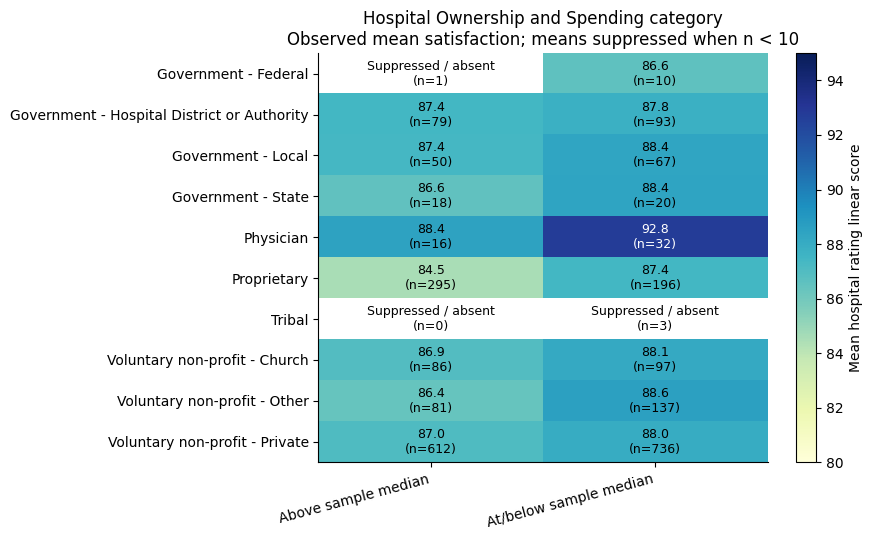

Emergency Services and Readmission category: 3,138 observed hospitals; 45 excluded for missing grouping values


,Emergency Services,Readmission category,hospitals,mean_score,median_score
0,No,At least one better,79,89.58,90.0
1,No,No measures better,111,88.46,89.0
2,Yes,At least one better,1390,88.17,88.0
3,Yes,No measures better,1558,87.41,88.0


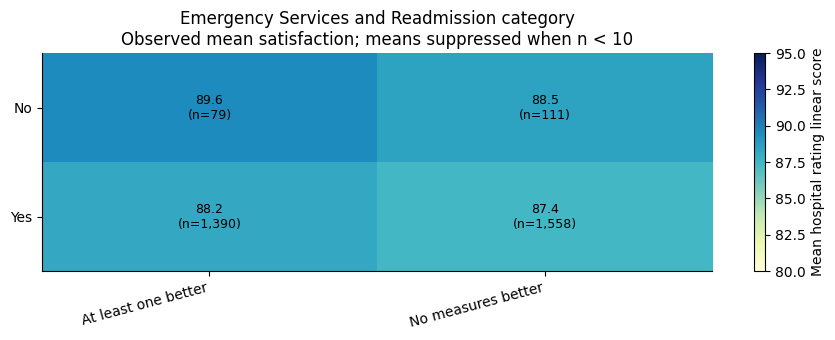

Hybrid mortality category and Spending category: 2,629 observed hospitals; 554 excluded for missing grouping values


,Hybrid mortality category,Spending category,hospitals,mean_score,median_score
0,Above sample median,Above sample median,629,86.1,86.0
1,Above sample median,At/below sample median,559,87.53,88.0
2,At/below sample median,Above sample median,609,86.8,87.0
3,At/below sample median,At/below sample median,832,88.45,89.0


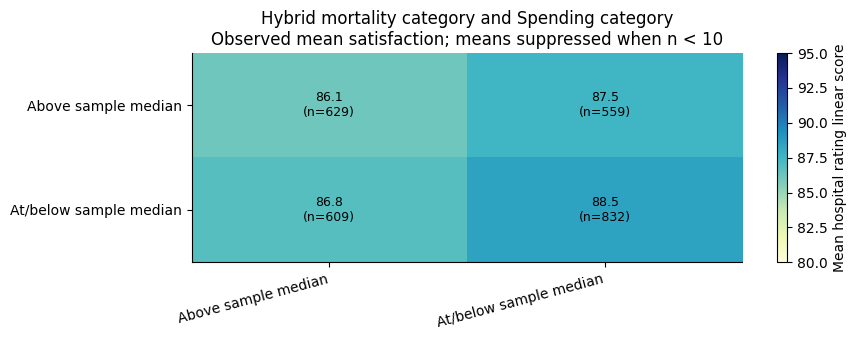

**What these comparisons establish:** the plots describe which observed combinations accompany higher or lower mean satisfaction and where coverage is limited. They do not show which group improves prediction. That question remains for models fitted and compared on identical folds, with uncertainty reported and the prior full-sample exploration disclosed.

In [15]:
spending_cut = scored["MSPB-1"].median()
hybrid_cut = scored["Hybrid_HWM"].median()
print(f"Descriptive median cutoffs: MSPB-1 = {spending_cut:.3f}; Hybrid_HWM = {hybrid_cut:.3f}")
combination_data = scored.copy()
combination_data["Spending category"] = pd.Series(pd.NA, index=scored.index, dtype="string")
combination_data.loc[scored["MSPB-1"].le(spending_cut), "Spending category"] = "At/below sample median"
combination_data.loc[scored["MSPB-1"].gt(spending_cut), "Spending category"] = "Above sample median"
combination_data["Hybrid mortality category"] = pd.Series(pd.NA, index=scored.index, dtype="string")
combination_data.loc[scored["Hybrid_HWM"].le(hybrid_cut), "Hybrid mortality category"] = "At/below sample median"
combination_data.loc[scored["Hybrid_HWM"].gt(hybrid_cut), "Hybrid mortality category"] = "Above sample median"
combination_data["Readmission category"] = pd.Series(pd.NA, index=scored.index, dtype="string")
combination_data.loc[scored["Readmission better proportion"].eq(0), "Readmission category"] = "No measures better"
combination_data.loc[scored["Readmission better proportion"].gt(0), "Readmission category"] = "At least one better"
combination_summaries = {}
for row_variable, col_variable in [
    ("Hospital Ownership", "Spending category"),
    ("Emergency Services", "Readmission category"),
    ("Hybrid mortality category", "Spending category"),
]:
    subset = combination_data.dropna(subset=[row_variable, col_variable])
    summary = subset.groupby([row_variable, col_variable], observed=True)["Hospital rating linear score"].agg(
        hospitals="count", mean_score="mean", median_score="median").reset_index()
    summary.loc[summary["hospitals"].lt(10), ["mean_score", "median_score"]] = np.nan
    name = f"{row_variable} and {col_variable}"
    combination_summaries[name] = summary
    print(f"{name}: {len(subset):,} observed hospitals; {len(scored) - len(subset):,} excluded for missing grouping values")
    display(summary.round(2))
    means = summary.pivot(index=row_variable, columns=col_variable, values="mean_score")
    counts = summary.pivot(index=row_variable, columns=col_variable, values="hospitals").fillna(0)
    fig, ax = plt.subplots(figsize=(9, max(3.5, .55 * len(means))))
    heat = ax.imshow(means.to_numpy(dtype=float), cmap="YlGnBu", vmin=80, vmax=95, aspect="auto")
    ax.set_xticks(range(len(means.columns)), means.columns, rotation=15, ha="right")
    ax.set_yticks(range(len(means.index)), means.index)
    for i in range(len(means)):
        for j in range(len(means.columns)):
            mean = means.iloc[i, j]
            count = int(counts.reindex(index=means.index, columns=means.columns).iloc[i, j])
            label = f"{mean:.1f}\n(n={count:,})" if pd.notna(mean) else f"Suppressed / absent\n(n={count:,})"
            ax.text(j, i, label, ha="center", va="center", fontsize=9,
                    color="white" if pd.notna(mean) and mean > 90 else "black")
    ax.set_title(name + "\nObserved mean satisfaction; means suppressed when n < 10")
    fig.colorbar(heat, ax=ax, label="Mean hospital rating linear score")
    plt.tight_layout()
    plt.show()

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
combination_coverage.to_csv(RESULTS_DIR / "predictor_group_coverage.csv", index=False)
predictor_correlations.to_csv(RESULTS_DIR / "selected_predictor_correlations.csv")
pair_counts.to_csv(RESULTS_DIR / "selected_predictor_pair_counts.csv")
for number, (name, summary) in enumerate(combination_summaries.items(), 1):
    summary.to_csv(RESULTS_DIR / f"predictor_combination_{number}.csv", index=False)
display(Markdown("**What these comparisons establish:** the plots describe which observed combinations accompany higher or lower mean satisfaction and where coverage is limited. They do not show which group improves prediction. That question remains for models fitted and compared on identical folds, with uncertainty reported and the prior full-sample exploration disclosed."))


## Build models

**Pending.** The planned comparison uses each of the four predictor groups, prespecified cumulative combinations, and all groups together, with a mean-score baseline. No models are fitted in this EDA. Using the same hospital sample and splits is necessary for a fair comparison; group-specific complete-case populations should not be compared as if only the predictors changed.

## Evaluate models

**Not started.** No predictive performance or cross-validation results are available. Future cross-validation must use raw training predictors with the unfitted preprocessor inside a model pipeline; the held-out test set must remain separate.

The planned group comparison will report MAE, RMSE, and R² on the same cross-validation folds. Entire pipelines, including imputation and categorical encoding, must be fitted inside training folds. Existing full-sample exploratory findings must be disclosed; the current split is not an untouched confirmatory evaluation after this exploration.

## Final results

**Interim descriptive findings only.** The project is not a completed predictive study. The following results summarize the work performed so far.

In [16]:
display(Markdown("## Findings for the selected predictors"))
display(Markdown(
    f"The reference population contains **{len(analysis):,} hospitals**, of which **{len(scored):,}** have a numeric satisfaction score. "
    f"Only **{complete_count:,}** have both a numeric target and all eight selected predictor summaries. "
    "This is an availability count; no complete-case sample is imposed and no rows are dropped from the reference table."
))
for feature, row in relationships.iterrows():
    if pd.notna(row["pearson_r"]):
        display(Markdown(f"- **{feature}:** {int(row['paired_hospitals']):,} paired hospitals; "
                         f"Pearson r = {row['pearson_r']:.3f}, Spearman rho = {row['spearman_rho']:.3f}."))
    else:
        display(Markdown(f"- **{feature}:** {int(row['paired_hospitals']):,} paired hospitals; "
                         "a correlation cannot be estimated because the sample or variation is insufficient."))
display(Markdown(
    "**Interpretation and limits.** A positive correlation means higher values tend to accompany higher satisfaction; "
    "a negative value means the opposite. These associations use different hospital subsets and should not be ranked as independent effects. "
    "A better proportion of zero means no classified measures were rated better; it does not mean all were rated worse. "
    "For small denominators a single measure changes the proportion substantially. "
    "Different measurement periods and nonrandom reporting limit comparisons. "
    "The extent of predictive performance remains unanswered at this stage: no prediction models have been fitted."
))


## Findings for the selected predictors

The reference population contains **5,419 hospitals**, of which **3,183** have a numeric satisfaction score. Only **2,612** have both a numeric target and all eight selected predictor summaries. This is an availability count; no complete-case sample is imposed and no rows are dropped from the reference table.

- **Mortality better proportion:** 3,131 paired hospitals; Pearson r = 0.019, Spearman rho = -0.000.

- **Safety better proportion:** 3,022 paired hospitals; Pearson r = -0.200, Spearman rho = -0.263.

- **Readmission better proportion:** 3,138 paired hospitals; Pearson r = 0.174, Spearman rho = 0.149.

- **Hybrid_HWM:** 3,148 paired hospitals; Pearson r = -0.076, Spearman rho = -0.056.

- **MSPB-1:** 2,629 paired hospitals; Pearson r = -0.313, Spearman rho = -0.286.

**Interpretation and limits.** A positive correlation means higher values tend to accompany higher satisfaction; a negative value means the opposite. These associations use different hospital subsets and should not be ranked as independent effects. A better proportion of zero means no classified measures were rated better; it does not mean all were rated worse. For small denominators a single measure changes the proportion substantially. Different measurement periods and nonrandom reporting limit comparisons. The extent of predictive performance remains unanswered at this stage: no prediction models have been fitted.

## Appendix: prior expanded correlation screen

This prior exploratory search is supplemental background. Other HCAHPS survey measures are outside the current research question and are not added to the selected predictors.

This additional exploration ranks numeric candidate variables by absolute Pearson correlation with the satisfaction target. The original selected predictors and missing-value preparation are unchanged. Correlations use **observed, pairwise-complete hospital values**, not imputed data. Pearson and Spearman correlations and matched sample sizes are reported. The ranking requires at least **100 paired hospitals** and variation in both variables; all candidates and exclusion reasons remain in the full results file. This threshold is a screening rule, not a guarantee of reliability.

Candidates include numeric General Information measure counts and ratings, clinical outcome and spending scores, HCAHPS percentage/linear/star measures, and survey response rate and completed-survey counts. The earlier three better-proportion features are included. Emergency Services and birthing-friendly designation are separately labeled binary comparisons; nominal hospital type and ownership are not assigned arbitrary numeric codes. Identifiers, addresses, phone numbers, dates, footnote codes, confidence-limit endpoints, and clinical denominators are not treated as independent clinical predictors.

Results distinguish **other HCAHPS survey measures**, **same-target transformations and overlapping ratings**, and **non-HCAHPS candidates**. Target-derived ratings/response percentages and the HCAHPS summary star rating are overlap diagnostics, not proposed predictors. Other HCAHPS measures use the same respondents and may be strongly associated for that reason. General Information's overall star rating includes patient experience, so it is also flagged. These exploratory ranks are not validated feature selection, significance tests, or independent effects. Many comparisons increase the chance of finding sample-specific associations; future evaluation should repeat feature selection inside training folds.


Screened 116 candidates; 109 meet the ranking rule.


**Strongest non-HCAHPS numeric associations**

,source,variable,description,paired_hospitals,pearson_r,spearman_rho
5,General Information,Count of MORT Measures No Different,Count of MORT Measures No Different,3131,-0.355,-0.386
3,General Information,Count of Facility MORT Measures,Count of Facility MORT Measures,3131,-0.353,-0.367
8,General Information,Count of Facility Safety Measures,Count of Facility Safety Measures,3022,-0.329,-0.322
46,Medicare Spending,MSPB-1,Medicare hospital spending per patient (Medica...,2629,-0.313,-0.286
10,General Information,Count of Safety Measures No Different,Count of Safety Measures No Different,3022,-0.289,-0.309
16,General Information,Count of READM Measures Worse,Count of READM Measures Worse,3138,-0.282,-0.308
13,General Information,Count of Facility READM Measures,Count of Facility READM Measures,3138,-0.236,-0.268
20,General Information,Count of Facility TE Measures,Count of Facility TE Measures,3144,-0.216,-0.194
9,General Information,Count of Safety Measures Better,Count of Safety Measures Better,3022,-0.204,-0.285
24,Derived General Information,Safety better proportion,Safety better proportion,3022,-0.200,-0.263


**Strongest associations within the same HCAHPS survey**

,source,variable,description,paired_hospitals,pearson_r,spearman_rho
105,HCAHPS,H_RECMND_LINEAR_SCORE | HCAHPS Linear Mean Value,Recommend hospital - linear mean score,3183,0.948,0.936
104,HCAHPS,H_RECMND_DY | HCAHPS Answer Percent,"Patients who reported YES, they would definite...",3183,0.907,0.900
107,HCAHPS,H_RECMND_STAR_RATING | Patient Survey Star Rating,Recommend hospital - star rating,3183,0.895,0.901
53,HCAHPS,H_COMP_1_LINEAR_SCORE | HCAHPS Linear Mean Value,Nurse communication - linear mean score,3183,0.869,0.848
103,HCAHPS,H_RECMND_DN | HCAHPS Answer Percent,"Patients who reported NO, they would probably ...",3183,-0.865,-0.883
52,HCAHPS,H_COMP_1_A_P | HCAHPS Answer Percent,"Patients who reported that their nurses ""Alway...",3183,0.833,0.811
55,HCAHPS,H_COMP_1_STAR_RATING | Patient Survey Star Rating,Nurse communication - star rating,3183,0.825,0.825
54,HCAHPS,H_COMP_1_SN_P | HCAHPS Answer Percent,"Patients who reported that their nurses ""Somet...",3183,-0.821,-0.799
95,HCAHPS,H_NURSE_RESPECT_A_P | HCAHPS Answer Percent,"Patients who reported that their nurses ""Alway...",3183,0.819,0.791
90,HCAHPS,H_NURSE_EXPLAIN_SN_P | HCAHPS Answer Percent,"Patients who reported that their nurses ""Somet...",3183,-0.807,-0.775


...

,source,variable,description,paired_hospitals,pearson_r,spearman_rho
115,HCAHPS,Survey Response Rate Percent,Survey Response Rate Percent,3183,0.514,0.493
114,HCAHPS,Number of Completed Surveys,Number of Completed Surveys,3183,-0.055,-0.249


**Binary characteristic comparisons**

,source,variable,description,paired_hospitals,pearson_r,spearman_rho
21,General Information,Emergency Services,Emergency Services (observed binary coding),3183,-0.076,-0.086


**Not ranked: insufficient variation or too few paired hospitals**

,source,variable,paired_hospitals,ranking_status
0,General Information,County/Parish,0,insufficient variation
2,General Information,MORT Group Measure Count,3154,insufficient variation
7,General Information,Safety Group Measure Count,3154,insufficient variation
12,General Information,READM Group Measure Count,3154,insufficient variation
17,General Information,Pt Exp Group Measure Count,3154,insufficient variation
19,General Information,TE Group Measure Count,3154,insufficient variation
22,General Information,Meets criteria for birthing friendly designation,2150,insufficient variation


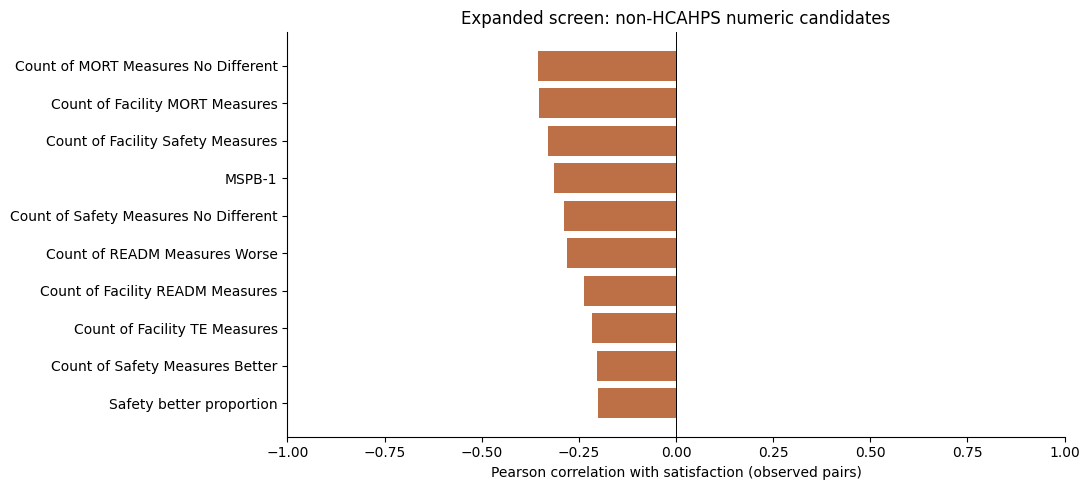

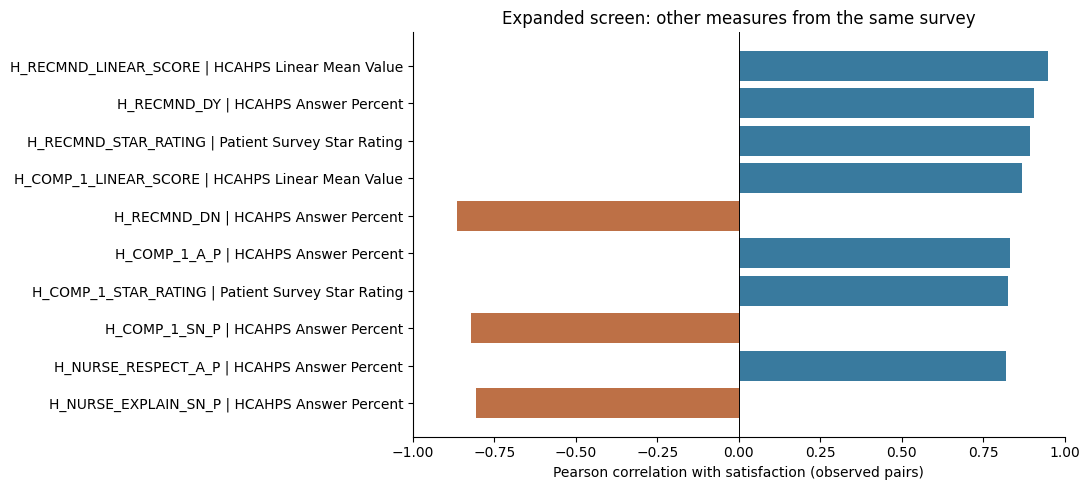

**Outside HCAHPS and overlapping ratings:** the largest absolute Pearson correlation is for **Count of MORT Measures No Different** (`Count of MORT Measures No Different`): **r = -0.355**, Spearman rho = -0.386, based on **3,131 hospitals**.

**Among other same-survey measures:** the largest absolute Pearson correlation is for **Recommend hospital - linear mean score** (`H_RECMND_LINEAR_SCORE | HCAHPS Linear Mean Value`): **r = 0.948**, Spearman rho = 0.936, based on **3,183 hospitals**.

These ranks compare different available hospital subsets and many related variables. They do not establish which variable has the strongest independent effect or out-of-sample predictive value. The existing selected-predictor analysis and preprocessing remain unchanged.

In [17]:
# Exploratory screen only: does not alter features, X_train, X_test, or preprocessing.
reference_ids = set(general["Facility ID"])
screen_target = pd.Series(target_numeric.to_numpy(), index=target_rows["Facility ID"], dtype=float)
screen_target = screen_target.loc[screen_target.index.isin(reference_ids)]
candidates = []

def add_candidate(source_name, variable, label, series, category):
    assert series.index.is_unique, f"Duplicate hospital IDs: {variable}"
    numeric = pd.to_numeric(series, errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)
    pair = pd.concat([screen_target.rename("target"), numeric.rename("candidate")], axis=1).dropna()
    varying = len(pair) >= 3 and pair["candidate"].nunique() > 1 and pair["target"].nunique() > 1
    candidates.append({"source": source_name, "variable": variable, "description": label,
                       "category": category, "paired_hospitals": len(pair),
                       "target_coverage_percent": 100 * len(pair) / len(screen_target.dropna()),
                       "pearson_r": pair["target"].corr(pair["candidate"]) if varying else np.nan,
                       "spearman_rho": pair["target"].corr(pair["candidate"], method="spearman") if varying else np.nan,
                       "ranking_status": "eligible" if varying and len(pair) >= 100 else
                           ("insufficient variation" if not varying else "fewer than 100 pairs")})

# Numeric counts and the overall rating; administrative numeric codes are excluded.
for col in general.columns:
    if "Count" in col or col == "Hospital overall rating":
        category = "Overlapping rating / target transformation" if col == "Hospital overall rating" else "Non-HCAHPS numeric candidate"
        add_candidate("General Information", col, col, general.set_index("Facility ID")[col], category)
for col, mapping in [("Emergency Services", {"Yes": 1, "No": 0}),
                     ("Meets criteria for birthing friendly designation", {"Y": 1})]:
    # A blank birthing designation is not assumed to mean No.
    add_candidate("General Information", col, col + " (observed binary coding)",
                  general.set_index("Facility ID")[col].map(mapping), "Binary characteristic")
for feature in performance_features:
    add_candidate("Derived General Information", feature, feature,
                  analysis.set_index("Facility ID")[feature], "Non-HCAHPS numeric candidate")
for source_name, dataset_key in [("Complications and Deaths", "outcomes"), ("Medicare Spending", "spending")]:
    for measure, group in datasets[dataset_key].groupby("Measure ID"):
        add_candidate(source_name, measure, group["Measure Name"].iloc[0], group.set_index("Facility ID")["Score"],
                      "Non-HCAHPS numeric candidate")
for measure, group in hcahps.groupby("HCAHPS Measure ID"):
    if measure == TARGET_MEASURE:
        continue  # Never correlate the target with itself.
    category = ("Overlapping rating / target transformation" if measure.startswith("H_HSP_RATING") or measure == "H_STAR_RATING"
                else "Other HCAHPS survey measure")
    for value_col in ["HCAHPS Answer Percent", "HCAHPS Linear Mean Value", "Patient Survey Star Rating"]:
        if pd.to_numeric(group[value_col], errors="coerce").notna().any():
            add_candidate("HCAHPS", f"{measure} | {value_col}", group["HCAHPS Question"].iloc[0],
                          group.set_index("Facility ID")[value_col], category)
for col in ["Number of Completed Surveys", "Survey Response Rate Percent"]:
    add_candidate("HCAHPS", col, col, target_rows.set_index("Facility ID")[col], "Survey reporting characteristic")

correlation_screen = pd.DataFrame(candidates)
correlation_screen["absolute_pearson_r"] = correlation_screen["pearson_r"].abs()
correlation_screen = correlation_screen.sort_values("absolute_pearson_r", ascending=False, na_position="last")
ranked_correlations = correlation_screen.loc[correlation_screen["ranking_status"].eq("eligible")].copy()
columns_to_show = ["source", "variable", "description", "paired_hospitals", "pearson_r", "spearman_rho"]
print(f"Screened {len(correlation_screen)} candidates; {len(ranked_correlations)} meet the ranking rule.")
for category, title in [
    ("Non-HCAHPS numeric candidate", "Strongest non-HCAHPS numeric associations"),
    ("Other HCAHPS survey measure", "Strongest associations within the same HCAHPS survey"),
    ("Overlapping rating / target transformation", "Overlapping ratings and target transformations: diagnostics only"),
    ("Survey reporting characteristic", "Survey reporting characteristics"),
    ("Binary characteristic", "Binary characteristic comparisons"),
]:
    subset = ranked_correlations.loc[ranked_correlations["category"].eq(category)]
    display(Markdown(f"**{title}**"))
    display(subset[columns_to_show].head(10).round(3))

excluded_candidates = correlation_screen.loc[~correlation_screen["ranking_status"].eq("eligible")]
if len(excluded_candidates):
    display(Markdown("**Not ranked: insufficient variation or too few paired hospitals**"))
    display(excluded_candidates[["source", "variable", "paired_hospitals", "ranking_status"]])

for category, title in [("Non-HCAHPS numeric candidate", "Expanded screen: non-HCAHPS numeric candidates"),
                        ("Other HCAHPS survey measure", "Expanded screen: other measures from the same survey")]:
    plotted = ranked_correlations.loc[ranked_correlations["category"].eq(category)].head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.barh(plotted["variable"], plotted["pearson_r"], color=np.where(plotted["pearson_r"].ge(0), "#397a9e", "#bd7046"))
    ax.axvline(0, color="black", linewidth=.7)
    ax.set(xlim=(-1, 1), xlabel="Pearson correlation with satisfaction (observed pairs)", title=title)
    plt.tight_layout()
    plt.show()

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
correlation_screen.to_csv(RESULTS_DIR / "expanded_correlations.csv", index=False)
for category, label in [("Non-HCAHPS numeric candidate", "Outside HCAHPS and overlapping ratings"),
                        ("Other HCAHPS survey measure", "Among other same-survey measures")]:
    top = ranked_correlations.loc[ranked_correlations["category"].eq(category)].iloc[0]
    display(Markdown(f"**{label}:** the largest absolute Pearson correlation is for **{top['description']}** "
                     f"(`{top['variable']}`): **r = {top['pearson_r']:.3f}**, "
                     f"Spearman rho = {top['spearman_rho']:.3f}, based on **{int(top['paired_hospitals']):,} hospitals**."))
display(Markdown("These ranks compare different available hospital subsets and many related variables. "
                 "They do not establish which variable has the strongest independent effect or out-of-sample predictive value. "
                 "The existing selected-predictor analysis and preprocessing remain unchanged."))


## Sources and limits

The supplied local CSVs are the source for all counts, dates, and descriptive statistics above. Their SHA-256 hashes are recorded near the start. Download and release dates were not supplied, so they are not inferred.

- [CMS hospital data catalog](https://data.cms.gov/provider-data/topics/hospitals)
- [CMS HCAHPS hospital dataset](https://data.cms.gov/provider-data/dataset/dgck-syfz)
- [CMS HCAHPS overview](https://www.cms.gov/data-research/research/consumer-assessment-healthcare-providers-systems/hospital-cahps-hcahps)

The intended 0–100 target scale comes from the project specification; the observed values and labels are verified in the CSV. The accompanying release dictionary was not included in the supplied files. Any later feature selection should consider information leakage: the CMS overall hospital star rating includes patient experience, and other HCAHPS measures share the same survey as the target. This notebook does not use those fields to predict the target.

## AI usage disclosure

- **AI tool/model:** OpenAI Codex (GPT-6-based coding assistant).
- **Used for:** Project setup, CMS-file inspection, notebook code and explanatory text, descriptive analysis, missing-value preparation, and adaptation to the DS 3001 repository template.
- **How the work was verified:** The assistant inspected the supplied CSV headers and measure labels; ran the notebook end to end; validated notebook structure; checked hospital/measure uniqueness, one-to-one joins, target ranges, train/test separation, and missing values after preprocessing. Written results were checked against executed outputs. Independent team review has not been documented.
- **Prompts used (selected verbatim prompts from this conversation):**
  - “actually for now can you jsut do the initial data exploration”
  - “we are onyl goin gto use these: Hospital Type/Ownership, Emergency Services, Mortality/Safety/Readmission Performance, Hybrid_HWM, MSPB-1​”
  - “can you update the eplxiarion to reflect this”
  - “can you resolve the second step” (referring to missing target and predictor values)
  - “can you follow this template for the repo: [https://github.com/sds3001/project_template](https://github.com/sds3001/project_template)”

This list is a selection, not a complete prompt transcript; the team should retain the full conversation for any course requirement to disclose every prompt.

Additional prompt used: “can you look through the datasets and find the strongest correlated vairbales”. Codex added and executed a broader numeric correlation screen with sample sizes and explicit overlap flags.

Additional prompt: “i think we will focus on this question then. can you update the eda to reflect this”. Updated the question and added predictor-group coverage, predictor correlations, and descriptive combination comparisons; no model evaluation was performed.